# From genotype calls to a genetic map

This notebook explains the machinery behind the study: how a row of genotype measurements becomes a point, why PCA chooses those coordinates, what geographic alignment is allowed to change, and how supervised prediction differs from the PCA result.

We use two kinds of evidence: **small, explicitly invented examples** for calculations you can inspect by hand, and the **actual 996-person dataset** for the study. Toy outputs are never substituted for scientific results. View the [technical report](genes_mirror_geography_replication.ipynb).

The path is: genotype counts → quality control → normalization → covariance and SVD → scores and reconstruction → real-data PCA → geographic alignment → sensitivity → regression → neural networks → losses and validation.

## 1. Notation and environment

Run cells in order. Tables and figures appear directly below their cells. The `results/teaching_notebook/` folders are scratch space for later real-data calculations; the setup cell creates them before they contain results.

| Symbol | Meaning | Shape in the current study |
|---|---|---|
| $G$ | Genotype calls, people × markers | $996\times46{,}213$ after QC |
| $p$ | Reference allele frequency per marker | $46{,}213$ |
| $Z$ | Frequency-normalized calls, with missing values imputed | $996\times46{,}213$ |
| $X$ | Centered reference matrix | $428\times46{,}213$ |
| $V_k$ | $k$ feature directions, stored as columns mathematically | $46{,}213\times k$ |
| $P$ | Person scores in those directions | $996\times k$ |
| $Q,s$ | Orthogonal alignment matrix and one scalar scale | $2\times2$, scalar |

`@` means matrix multiplication; `*` multiplies element by element; `.T` transposes; `axis=0` reduces down rows, leaving one value per column. NumPy broadcasts a length-$m$ vector across an $n\times m$ matrix. Always check shapes before trusting a calculation.

### At-a-glance comparison

| Parameter | Novembre et al. (2008) | This replication (AADR v66) |
|---|---|---|
| Sample size (N) | 1,387 Europeans in the final POPRES analysis | 996 modern European records (date = 0; 672 .HO and 324 .DG) |
| Genotyping platform | Affymetrix 500K; 500,568 assayed loci | Human Origins-compatible data; 276,725-marker input manifest |
| Post-QC / LD-pruned SNPs (M) | 197,146 | 46,213; core-panel MAF ≥ 0.05 and sliding-window r² threshold 0.20 |
| Explained variance (PC1 + PC2) | Approximately 0.45% (0.30% + 0.15%) | 0.959% (0.580% + 0.379%) of reference-panel variance |
| Alignment of the displayed PCA | 16° counterclockwise rotation selected by geographic correlations (Figure 1) | One orthogonal Procrustes similarity transform: Q, one scale s, and translation; 52 equally weighted calibration centroids |

Source: Novembre et al. (2008), *Genes mirror geography within Europe*, Nature 456:98–101, especially Figure 1 and Methods. The original paper's geographic assignment uses separate regression models with quadratic and interaction terms; those are distinct from its PCA display rotation. Cohorts, marker sets and preprocessing differ, so the variance percentages are not comparable measures of geographic prediction accuracy.


In [2]:
from pathlib import Path
from contextlib import redirect_stdout
import io, sys, json, importlib, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown, HTML
from sklearn.decomposition import PCA

here = Path.cwd().resolve()
project = next(p for p in [here, *here.parents]
               if (p / "research/pipeline/run_human_origins_pca.py").exists())


research = project / "research"
sys.path.insert(0, str(research / "pipeline"))
import run_human_origins_pca as pipeline
importlib.reload(pipeline)

WORK = research / "results" / "teaching_notebook"

for attribute, folder in [("PROCESSED", "processed"), ("QC_DIR", "qc"),
                          ("STATS", "stats"), ("PLOTS", "plots"), ("WEBSITE_DATA", "atlas")]:
    directory = WORK / folder
    directory.mkdir(parents=True, exist_ok=True)
    setattr(pipeline, attribute, directory)
(WORK / "execution_details.txt").write_text("")


def run_step(function, *args):
    """Keep detailed processing logs on disk and show selected outputs below."""
    stream = io.StringIO()
    try:
        with redirect_stdout(stream):
            value = function(*args)
    finally:
        with (WORK / "execution_details.txt").open("a") as log:
            log.write(stream.getvalue())
    return value


def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
protected = [p for p in (project / "website").rglob("*") if p.is_file()]
protected += list((research / "pipeline").glob("*.py"))
protected += [p for d in ["results/stats", "results/plots"] for p in (research/d).glob("*")
              if p.is_file() and p.name != "notebook_execution.log"]
protected_hashes = {str(p.relative_to(project)): digest(p) for p in protected}
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "#fafcfb",
                     "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
region_colors = {"Northern & Nordic": "#00836f", "Western & Atlantic": "#2467ad",
                 "Iberia & Basque": "#bf4f55", "Mediterranean": "#a96318",
                 "Balkans & Southeast": "#477d44", "Central & Eastern": "#7753ba"}
region_handles = [Line2D([], [], marker="o", linestyle="", color=c, label=r)
                  for r,c in region_colors.items()]


def colors_for(frame):
    return [region_colors[pipeline.get_region_and_color(p)[0]] for p in frame.population]


def save_figure(fig, name):
    fig.savefig(pipeline.PLOTS / name, dpi=170, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def read_js_data(path):
    return json.loads(Path(path).read_text().split("=", 1)[1].strip().rstrip(";"))


def haversine_km(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.asarray, [lon1, lat1, lon2, lat2])
    a = np.sin(np.radians(lat2-lat1)/2)**2 + np.cos(np.radians(lat1))*np.cos(np.radians(lat2))*np.sin(np.radians(lon2-lon1)/2)**2
    return 2*6371*np.arcsin(np.sqrt(np.clip(a, 0, 1)))

run_step(pipeline.chunk_1_verify_environment)
print("Inputs verified. Run the remaining cells to see tables and figures inline.")
print("Scratch files and processing logs, created by later cells:", WORK.relative_to(project))

Inputs verified. Run the remaining cells to see tables and figures inline.
Scratch files and processing logs, created by later cells: research/results/teaching_notebook


## 2. Turning a SNP into a number

A SNP is a site where a single DNA base can vary. For a biallelic autosomal marker, choose one allele to count. A diploid genotype contributes 0, 1 or 2 copies. For example, if G is the counted allele, AA → 0, AG → 1, GG → 2. The coding identifies dosage, not the complete DNA sequence; count 1 alone does not tell us which bases were involved.

Each person is one row and each SNP is one column. Missing is `NaN`, not zero: zero is an observed genotype. Here is a deliberately small invented dataset. The last two columns happen to be correlated, which will help illustrate redundant information.

In [3]:
toy_G = np.array([[0, 0, 2, 0, 0],
                  [0, 1, 2, 1, 1],
                  [1, 0, 1, 1, 1],
                  [1, 2, 1, 1, np.nan],
                  [2, 1, 0, 2, 2],
                  [2, 2, 0, 2, 2]], dtype=float)
toy_ids = [f"Toy person {i}" for i in range(1, 7)]
display(pd.DataFrame(toy_G, index=toy_ids, columns=[f"SNP {j}" for j in range(1, 6)]))

,SNP 1,SNP 2,SNP 3,SNP 4,SNP 5
Toy person 1,0.0,0.0,2.0,0.0,0.0
Toy person 2,0.0,1.0,2.0,1.0,1.0
Toy person 3,1.0,0.0,1.0,1.0,1.0
Toy person 4,1.0,2.0,1.0,1.0,NaN
Toy person 5,2.0,1.0,0.0,2.0,2.0
Toy person 6,2.0,2.0,0.0,2.0,2.0


### 2.1 How the binary file becomes that matrix

Two bits encode four states. In this TGENO file, codes `00`, `01`, `10`, `11` correspond to 0, 1, 2 and missing. Four calls occupy one byte, ordered from the least-significant pair of bits. To extract call $k$, shift right by $2k$ bits, then retain the last two bits with `& 3`.

The sample-major file stores an entire person's row together. The byte offset for sample index $i$ is $48+i\lceil M/4\rceil$, where $M$ is the number of markers in the original manifest. Marker filtering happens **after** unpacking that original row. Using the filtered marker count to calculate file offsets would read the wrong bytes. The real decoder also checks the TGENO header, file size and manifest dimensions. [Decoder source](pipeline/run_human_origins_pca.py).

**Measured call used in the atlas zoom.** The SVG-to-Canvas handoff uses the first column of the atlas’s displayed retained-marker window:

| Individual | rs2494432 · chromosome 1, position 2,349,769 · counted allele G |
|---|---|
| MOL-005.HO | GG → dosage 2 |

The call was checked against the raw TGENO byte, SNP manifest and retained-marker index. The atlas window uses 24 selected retained markers, rather than the first 24 columns of the full matrix. Its readable twelve-row excerpt expands to all 996 decoded rows. Flanking animation letters and parental roles are schematic; the genotype calls are unphased. Counting the first listed SNP allele follows the [EIGENSOFT format documentation](https://github.com/DReichLab/EIG/blob/master/CONVERTF/README).


In [4]:
example_codes = np.array([0, 1, 2, 3], dtype=np.uint8)
packed = sum(int(value) << (2*k) for k, value in enumerate(example_codes))
unpacked = np.array([(packed >> (2*k)) & 3 for k in range(4)])
np.testing.assert_array_equal(unpacked, example_codes)
decoded = np.where(unpacked == 3, np.nan, unpacked.astype(float))
display(pd.DataFrame({"Position in byte": range(4), "Stored code": unpacked, "Decoded call": decoded}))
print("Packed byte:", packed, "| binary:", format(packed, "08b"))

Packed byte: 228 | binary: 11100100


,Position in byte,Stored code,Decoded call
0,0,0,0.0
1,1,1,1.0
2,2,2,2.0
3,3,3,NaN


## 3. Quality control: choose measurements that enter the PCA algorithm?

For marker $j$, let $n_j$ be the number of observed people in the chosen QC panel. The estimated counted-allele frequency is

$$p_j=\frac{\sum_{\text{observed }i}G_{ij}}{2n_j},\qquad \mathrm{MAF}_j=\min(p_j,1-p_j).$$

The denominator counts observed chromosomes; missing people contribute neither zero alleles nor two observed chromosomes. Call rate is the observed fraction. A marker with frequency 0.98 has minor-allele frequency 0.02 even if the counted allele is called “alternative.”

Our actual marker filter requires complete calls and MAF ≥0.05 in the **407-person core QC panel**. The **428-person PCA reference** is a different set with a different purpose. These are study choices, not universal thresholds. The toy calculation below uses all six made up genotypes for people for illustration.

In [5]:
toy_observed = np.isfinite(toy_G).sum(0)
toy_p = np.nansum(toy_G, axis=0)/(2*toy_observed)
toy_maf = np.minimum(toy_p, 1-toy_p)
display(pd.DataFrame({"Observed people": toy_observed, "Call rate": toy_observed/len(toy_G),
                      "Counted-allele frequency": toy_p, "MAF": toy_maf,
                      "Pass complete calls and MAF": (toy_observed == len(toy_G)) & (toy_maf >= .05)}))

,Observed people,Call rate,Counted-allele frequency,MAF,Pass complete calls and MAF
0,6,1.000000,0.500000,0.500000,True
1,6,1.000000,0.500000,0.500000,True
2,6,1.000000,0.500000,0.500000,True
3,6,1.000000,0.583333,0.416667,True
4,5,0.833333,0.600000,0.400000,False


### 3.1 Linkage disequilibrium and redundant columns

Nearby markers can be correlated, so many columns may repeat similar information. PCA maximizes variance; repeating a correlated block can give it disproportionate influence.

For standardized marker columns $a,b$, squared correlation is

$$r^2_{ab}=\left(\frac{1}{N}\sum_i\tilde G_{ia}\tilde G_{ib}\right)^2.$$

Here $\tilde G$ uses the empirical population standard deviation (`ddof=0`), so the divisor is $N$. Squaring treats strong positive and negative correlations equally. This empirical standardization for LD is distinct from the allele-frequency normalization used for PCA.

The implemented greedy filter walks 50-marker windows in five-marker steps, discarding later columns when $r^2>0.20$. It starts again on every chromosome, and only compares columns remaining in the current window. It does not prove all retained columns are independent. In this toy, SNPs 1–4 lie in one window; SNP 5 is on a different chromosome and is never compared to them.

In [6]:
base = np.array([0, 0, 1, 1, 2, 2], dtype=float)
ld_toy = np.column_stack([base, base, 2-base, [0, 2, 1, 1, 2, 0], base])
ld_chrom = np.array([1, 1, 1, 1, 2])
ld_Z = (ld_toy-ld_toy.mean(0))/ld_toy.std(0)
toy_r2 = (ld_Z.T @ ld_Z / len(ld_Z))**2
keep_toy = np.ones(ld_toy.shape[1], dtype=bool)


for chrom in np.unique(ld_chrom):
    indices = np.flatnonzero(ld_chrom == chrom)
    for a in indices:
        if not keep_toy[a]:
            continue
        for b in indices[indices > a]:
            if toy_r2[a, b] > .2:
                keep_toy[b] = False
assert np.flatnonzero(keep_toy).tolist() == [0, 3, 4]
display(pd.DataFrame(toy_r2.round(3), columns=[f"SNP {i}" for i in range(1, 6)]))
print("Retained toy SNPs (one-based):", (np.flatnonzero(keep_toy)+1).tolist())

Retained toy SNPs (one-based): [1, 4, 5]


,SNP 1,SNP 2,SNP 3,SNP 4,SNP 5
0,1.0,1.0,1.0,0.0,1.0
1,1.0,1.0,1.0,0.0,1.0
2,1.0,1.0,1.0,0.0,1.0
3,0.0,0.0,0.0,1.0,0.0
4,1.0,1.0,1.0,0.0,1.0


## 4. Why center and divide by $\sqrt{2p(1-p)}$?

A common allele naturally has a different dosage distribution from a rare one. Centering subtracts the expected count, scaling changes the units so columns are measured relative to a frequency based variance.

Write a diploid count as $G=A_1+A_2$. Under the Hardy–Weinberg reference model, each allele indicator has mean $p$ and variance $p(1-p)$, and the two copies are independent. Therefore

$$E[G]=2p,\qquad\operatorname{Var}(G)=2p(1-p),\qquad
Z=\frac{G-2p}{\sqrt{2p(1-p)}}.$$

This derives the normalizer; it does not prove that the study population satisfies Hardy–Weinberg assumptions. Structure and other effects can make the empirical variance differ. The population-genetic PCA motivation is discussed by [Patterson, Price & Reich](https://journals.plos.org/plosgenetics/article?id=10.1371/journal.pgen.0020190).

For $p=0.25$, the expected dosage is 0.5 and the denominator is $\sqrt{0.375}\approx0.6124$. Counts 0, 1 and 2 become approximately −0.8165, 0.8165 and 2.4495. A missing call is imputed at dosage $2p=0.5$, giving zero. Imputation supplies no positive or negative deviation; it also reduces variation at missing entries rather than recovering an unknown genotype.

In [7]:
worked_p = .25
worked_calls = np.array([0, 1, 2, np.nan])
worked_Z = np.nan_to_num((worked_calls-2*worked_p)/np.sqrt(2*worked_p*(1-worked_p)), nan=0.0)
display(pd.DataFrame({"Observed count": worked_calls, "Normalized value": worked_Z}).round(4))

toy_denominator = np.sqrt(2*toy_p*(1-toy_p))
toy_denominator[toy_denominator < 1e-6] = 1
toy_Z = np.nan_to_num((toy_G-2*toy_p)/toy_denominator, nan=0.0)
display(pd.DataFrame(toy_Z, index=toy_ids).round(3))

,Observed count,Normalized value
0,0.0,-0.8165
1,1.0,0.8165
2,2.0,2.4495
3,NaN,0.0000


,0,1,2,3,4
Toy person 1,-1.414,-1.414,1.414,-1.673,-1.732
Toy person 2,-1.414,0.000,1.414,-0.239,-0.289
Toy person 3,0.000,-1.414,0.000,-0.239,-0.289
Toy person 4,0.000,1.414,0.000,-0.239,0.000
Toy person 5,1.414,0.000,-1.414,1.195,1.155
Toy person 6,1.414,1.414,-1.414,1.195,1.155


**Reading the code.** `nanmean(G_reference, axis=0)/2` estimates one frequency per marker from the reference only. Subtracting `2*p` and dividing by the denominator broadcasts those marker-wise values over every person. `nan_to_num(..., nan=0.0)` handles missing calls after normalization. When a denominator is near zero we use 1 to avoid division by zero. A monomorphic reference column then has no reference variance and cannot define a varying reference axis.

The same reference frequencies must transform new people. Re-estimating frequencies separately for each new batch would change their coordinate system. Genotype normalization is performed before sklearn PCA; the estimator centers columns but does not apply this frequency scaling automatically. [PCA estimator conventions](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

## 5. PCA starts with a direction and a projection

Let $X=Z_{\mathrm{ref}}-\mu_{\mathrm{ref}}$ be the centered reference matrix. A feature direction $v$ assigns one weight to each SNP. For one person, the coordinate is the weighted sum $x_i^\top v$; for all reference people, it is $Xv$.

We constrain $\|v\|=1$: otherwise multiplying the weights by a thousand would multiply the variance without discovering anything. The sample covariance matrix is

$$C=\frac{X^\top X}{n_{\mathrm{ref}}-1}.$$

The variance along $v$ is $v^\top Cv$. Maximizing it under $v^\top v=1$ gives the Lagrangian
$\mathcal L=v^\top Cv-\lambda(v^\top v-1)$. Setting its derivative to zero gives $Cv=\lambda v$.

An **eigenvector** is a direction that $C$ scales without turning; its **eigenvalue** is the variance along that direction. PC1 chooses the largest eigenvalue. PC2 chooses the largest remaining direction orthogonal to PC1, and so on. Orthogonal means zero dot product, and leads to uncorrelated reference scores; it does not prove statistical independence or distinct biological causes.

In [8]:
toy_mean = toy_Z.mean(0)

toy_X = toy_Z-toy_mean

toy_C = toy_X.T @ toy_X/(len(toy_X)-1)

eigenvalues, eigenvectors = np.linalg.eigh(toy_C)

order = np.argsort(eigenvalues)[::-1]

eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]

np.testing.assert_allclose(toy_C @ eigenvectors, eigenvectors*eigenvalues, atol=1e-12)

display(pd.DataFrame(toy_C).round(3))


print("Eigenvalues in descending order:", np.round(eigenvalues, 5))

Eigenvalues in descending order: [ 5.87617e+00  1.01879e+00  2.34810e-01  2.60000e-03 -0.00000e+00]


,0,1,2,3,4
0,1.600,0.800,-1.600,1.217,1.225
1,0.800,1.600,-0.800,0.811,0.898
2,-1.600,-0.800,1.600,-1.217,-1.225
3,1.217,0.811,-1.217,1.166,1.159
4,1.225,0.898,-1.225,1.159,1.167


## 6. SVD gives the same geometry without a giant covariance matrix

With 46,213 markers, a dense covariance matrix would have over two billion entries. We need only a few leading directions. Singular value decomposition factors the centered matrix:

$$X=U\Sigma V^\top,\qquad
C=V\frac{\Sigma^2}{n_{\mathrm{ref}}-1}V^\top,\qquad
P_{\mathrm{ref}}=XV=U\Sigma.$$

$V$ contains marker weights, $U$ contains unit-length directions across people, and singular values in $\Sigma$ scale the scores. **The points we plot are scores, not SNP loadings.** sklearn stores feature directions as rows of `components_`, so its shape is $(k,m)$ and projection uses `components_.T`.

The real pipeline asks for ten components with `random_state=42` and the installed estimator's default solver selection. It may use an approximate leading-component algorithm; the manifest records the installed version. Our small example uses a full SVD so we can compare it directly to covariance eigenanalysis.

In [9]:
toy_U, toy_singular, toy_Vt = np.linalg.svd(toy_X, full_matrices=False)

toy_scores = toy_X @ toy_Vt.T

np.testing.assert_allclose(toy_scores, toy_U*toy_singular, atol=1e-12)
np.testing.assert_allclose(eigenvalues, toy_singular**2/(len(toy_X)-1), atol=1e-12)

toy_model = PCA(n_components=2, svd_solver="full").fit(toy_Z)
sklearn_scores = toy_model.transform(toy_Z)

# Eigenvector signs are arbitrary, align signs for this numerical comparison

signs = np.sign((toy_model.components_*toy_Vt[:2]).sum(axis=1))
np.testing.assert_allclose(sklearn_scores*signs, toy_scores[:, :2], atol=1e-10)
display(pd.DataFrame({"PC": np.arange(1, 6), "Singular value": toy_singular,
                      "Eigenvalue / variance": eigenvalues}).round(5))

,PC,Singular value,Eigenvalue / variance
0,1,5.42041,5.87617
1,2,2.25698,1.01879
2,3,1.08354,0.23481
3,4,0.11405,0.00260
4,5,0.00000,-0.00000


### 6.1 Follow one person into the coordinate plane

For PC1, multiply each centered SNP value by the corresponding PC1 loading and sum. Repeat with PC2's loading vector. Thousands of measurements contribute to two coordinates; the person does not literally become two measurements.

Changing $v$ to $-v$ changes every associated score's sign and leaves the geometry unchanged. The sign is not an east/west or ancestral label. Near-equal eigenvalues can also make individual directions unstable while their joint subspace is more stable.

Sum of contributions: -3.388806585528168 | PC1 score: -3.388806585528168


,Centered SNP value,PC1 weight,Contribution
0,-1.4142,0.5002,-0.7073
1,-1.4142,0.3593,-0.5081
2,1.4142,-0.5002,-0.7073
3,-1.6733,0.4271,-0.7147
4,-1.7321,0.4338,-0.7514


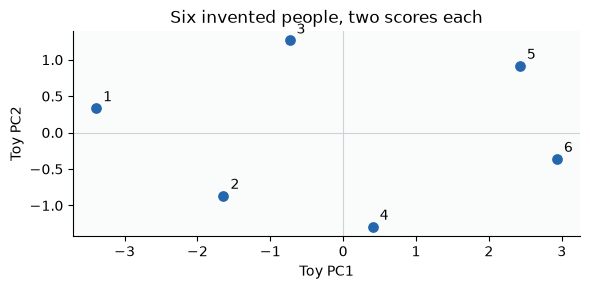

In [10]:
person_index = 0
contribution = toy_X[person_index]*toy_Vt[0]

display(pd.DataFrame({"Centered SNP value": toy_X[person_index], "PC1 weight": toy_Vt[0],
                      "Contribution": contribution}).round(4))

print("Sum of contributions:", contribution.sum(), "| PC1 score:", toy_scores[person_index, 0])

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(*toy_scores[:, :2].T, color="#2467ad", s=45)

for i, xy in enumerate(toy_scores[:, :2]):
    ax.annotate(str(i+1), xy, xytext=(5, 5), textcoords="offset points")

ax.axhline(0, color="#c7d5d8", lw=.8); ax.axvline(0, color="#c7d5d8", lw=.8)

ax.set_aspect("equal"); ax.set(xlabel="Toy PC1", ylabel="Toy PC2", title="Six invented people, two scores each")

fig.tight_layout(); save_figure(fig, "toy_person_scores.png")

## 7. What does dimensionality reduction throw away?

Keeping $k$ components gives the approximation

$$\hat X_k=(XV_k)V_k^\top=U_k\Sigma_kV_k^\top.$$

Among rank-$k$ matrices, truncated SVD minimizes the sum of squared reconstruction errors. The discarded error is $\|X-\hat X_k\|_F^2=\sum_{j>k}\sigma_j^2$. This is an error in normalized genotype space, **not** an error in geographic kilometres.

Explained-variance ratio is $\sigma_k^2/\sum_j\sigma_j^2$, with the denominator including all variation, even when we request only ten components. Later components can contain structure, artifacts, and noise; the component number alone does not tell us which. PCA optimizes retained variance, not geographic recognizability.

No whitening is used here. Dividing each score axis by its own standard deviation would change relative axis lengths and therefore change the displayed shape.

In [11]:
reconstruction_rows = []

for k in range(1, len(toy_singular)+1):
    reconstruction = (toy_X @ toy_Vt[:k].T) @ toy_Vt[:k]
    error = np.square(toy_X-reconstruction).sum()
    discarded = np.square(toy_singular[k:]).sum()
    np.testing.assert_allclose(error, discarded, atol=1e-12)
    reconstruction_rows.append({"PCs": k, "Squared reconstruction error": error,
        "Variance retained (%)": 100*np.square(toy_singular[:k]).sum()/np.square(toy_singular).sum()})
    
display(pd.DataFrame(reconstruction_rows).round(4))

,PCs,Squared reconstruction error,Variance retained (%)
0,1,6.2810,82.3872
1,2,1.1871,96.6713
2,3,0.0130,99.9635
3,4,0.0000,100.0000
4,5,0.0000,100.0000


## 8. Run the actual study


The analysis uses **996 modern individuals, 52 regional groups and 26 country labels** from the local AADR v66 Human Origins-compatible release. The **428-person PCA reference** and the **407-person core marker-QC panel** have different roles: the former defines the genetic axes; the latter determines call-rate, allele-frequency and LD filters.

Selection requires an explicit numeric date of zero, the predefined European population/platform scope, and one record per individual ID, preferring `.HO` and then higher coverage. The existing publication, population and six-ID relatedness exclusions remain part of the design; their rationale and relatedness estimates are not independently revalidated here. The reference uses fixed group quotas, so it is not a representative random sample. Full details are in [the selection implementation](pipeline/run_human_origins_pca.py) and [reference membership](pipeline/cohort_reference.json).

Locations are annotation localities or labeled proxies, including the assigned Tuscany location. They are not verified individual birthplaces. Country and regional labels annotate the figures after PCA; coordinates do not enter the PCA fit.


The next cells read actual measurements, apply the specified marker filters, and fit the reference. Routine selection and binary-decoding details live in the linked implementation; the numerical PCA operations remain visible here.

In [12]:
cohort = run_step(pipeline.chunk_2_cohort_selection)
assert len(cohort) == 996 and cohort.sample_id.is_unique
display(pd.Series({
    "Individuals": len(cohort), "Regional groups": cohort.population.nunique(),
    "Country labels": cohort.country.nunique(),
    "PCA reference individuals": int(cohort.is_pca_reference.sum()),
    "Marker-QC panel individuals": int(cohort.is_core_ho.sum())
}, name="Study design").to_frame())

display(cohort.groupby("coordinate_source").size().rename("Individuals").to_frame())

,Study design
Individuals,996
Regional groups,52
Country labels,26
PCA reference individuals,428
Marker-QC panel individuals,407


,Individuals
coordinate_source,
AADR annotation,775
Assigned Tuscany proxy,107
Assigned locality proxy,114


In [13]:
snp_manifest, eligible_snps = run_step(pipeline.chunk_3_snp_manifest_and_inversion_qc)

G_all = run_step(pipeline.chunk_4_binary_genotype_extraction, cohort, snp_manifest, eligible_snps)
assert np.isin(G_all[np.isfinite(G_all)], [0, 1, 2]).all()

display(pd.DataFrame(G_all[:5, :8], index=cohort.sample_id.iloc[:5],
                     columns=eligible_snps.snpid.iloc[:8]))

print("Observed dosage matrix:", G_all.shape, "— rows are people; columns are markers.")

Observed dosage matrix: (996, 273738) — rows are people; columns are markers.


snpid,rs7419119,rs13302957,rs9442372,rs147606383,rs4970405,rs1320571,rs3813199,rs61559999
sample_id,,,,,,,,
MOL-005.HO,2.0,1.0,0.0,2.0,2.0,2.0,2.0,1.0
MOL-008.HO,2.0,2.0,0.0,2.0,2.0,2.0,2.0,2.0
MOL-015.HO,2.0,0.0,1.0,2.0,2.0,2.0,2.0,2.0
MOL-024.HO,2.0,1.0,0.0,1.0,2.0,2.0,2.0,2.0
MOL-058.HO,2.0,0.0,1.0,1.0,2.0,2.0,2.0,2.0


In [14]:
core = cohort.is_core_ho.to_numpy()

complete_core = np.isfinite(G_all[core]).all(axis=0)

G_maf, snp_qc = run_step(pipeline.chunk_5_quality_control, G_all, eligible_snps, cohort)

qc_counts = {"Array markers": len(snp_manifest),
             "Eligible autosomal markers": G_all.shape[1],
             "Complete calls in the QC panel": int(complete_core.sum()),
             "MAF at least 5% in that panel": G_maf.shape[1]}
del G_all
G_pruned, retained_snps = run_step(pipeline.chunk_6_ld_pruning, G_maf, snp_qc, cohort)
del G_maf
assert G_pruned.shape == (996, 46213)

qc_counts["After chromosome-local LD pruning"] = G_pruned.shape[1]
display(pd.Series(qc_counts, name="Markers").to_frame())

print("Minimum individual call rate:", round(float(cohort.autosomal_call_rate.min()), 5))

Minimum individual call rate: 0.95691


,Markers
Array markers,276725
Eligible autosomal markers,273738
Complete calls in the QC panel,164190
MAF at least 5% in that panel,84118
After chromosome-local LD pruning,46213


### 8.1 the real PCA code line by line

1. `reference_mask` selects the rows that may define frequencies and axes.
2. `p` and `denominator` are length-46,213 vectors computed from those rows.
3. `Z_reference` is 428 × 46,213; `Z_all` is 996 × 46,213, using the same normalization.
4. `fit` learns the reference center and directions. It never receives longitude, latitude or country.
5. `transform` projects all people with those fixed directions. Its 996 × 10 result becomes the score columns.
6. The numerical check explicitly multiplies five rows by the component matrix and verifies agreement with `transform`

This is the same operation as [the final pipeline's `chunk_7_pca`](pipeline/run_human_origins_pca.py)

In [15]:

reference_mask = cohort.is_pca_reference.to_numpy()
G_reference = G_pruned[reference_mask]
p = np.nanmean(G_reference, axis=0) / 2
denominator = np.sqrt(2*p*(1-p))
denominator[denominator < 1e-6] = 1
Z_reference = np.nan_to_num((G_reference - 2*p) / denominator, nan=0.0)
Z_all = np.nan_to_num((G_pruned - 2*p) / denominator, nan=0.0)

model = PCA(n_components=10, random_state=42)
model.fit(Z_reference)
scores = model.transform(Z_all)
variance_pct = model.explained_variance_ratio_ * 100
results = cohort.copy()

for k in range(10):
    results[f"PC{k+1}"] = scores[:, k].astype(float)

np.testing.assert_allclose(
    (Z_all[:5] - model.mean_) @ model.components_.T,
    scores[:5], atol=2e-5, rtol=2e-5)

print("Reference matrix:", Z_reference.shape, "| projected scores:", scores.shape)

display(pd.DataFrame({"PC": np.arange(1, 11), "Reference variance (%)": variance_pct}).round(4))

Reference matrix: (428, 46213) | projected scores: (996, 10)


,PC,Reference variance (%)
0,1,0.5797
1,2,0.3789
2,3,0.2803
3,4,0.2772
4,5,0.2707
5,6,0.2689
6,7,0.2677
7,8,0.2669
8,9,0.2658
9,10,0.2647


In [16]:
# Inspect the arithmetic of one real person's PC1.
real_contribution = (Z_all[0]-model.mean_)*model.components_[0]
largest = np.argsort(np.abs(real_contribution))[-8:][::-1]
display(pd.DataFrame({"Marker": retained_snps.snpid.iloc[largest].to_numpy(),
                      "Observed call": G_pruned[0, largest],
                      "Centered normalized call": (Z_all[0]-model.mean_)[largest],
                      "PC1 loading": model.components_[0, largest],
                      "Contribution": real_contribution[largest]}).round(5))
print("Person:", results.sample_id.iloc[0])
print("Shown contributions:", real_contribution[largest].sum())
print("All other contributions:", real_contribution.sum()-real_contribution[largest].sum())
print("Total PC1:", real_contribution.sum(), "| transform output:", scores[0, 0])
np.testing.assert_allclose(real_contribution.sum(), scores[0, 0], atol=2e-5, rtol=2e-5)

Person: MOL-005.HO
Shown contributions: 0.1888363
All other contributions: 8.802658
Total PC1: 8.991494 | transform output: 8.991491


,Marker,Observed call,Centered normalized call,PC1 loading,Contribution
0,rs4131568,0.0,-6.00370,-0.00822,0.04934
1,rs140015486,0.0,-4.07538,-0.01195,0.04871
2,rs77108305,0.0,-5.23911,-0.00904,0.04738
3,rs77809119,0.0,-3.21194,-0.01461,0.04691
4,rs7209651,0.0,-3.70222,0.01206,-0.04464
5,rs12891732,0.0,-4.93340,0.00857,-0.04226
6,rs77115995,2.0,3.15785,0.01332,0.04205
7,rs9627139,0.0,-4.49242,-0.00920,0.04135


The table shows large numerical contributions to **one person's score**. It is not a ranking of causal genes or universal marker importance. A marker contributes through both its loading and that person's centered call.

In this dataset the first two components explain only about 0.959% of reference variation. A small percentage can still yield a visible pattern across individuals when there are many variable markers. It does not mean the map is “0.959% accurate,” and the map does not describe the remaining variation.

The first two PCs explain 0.9586% of reference variation.


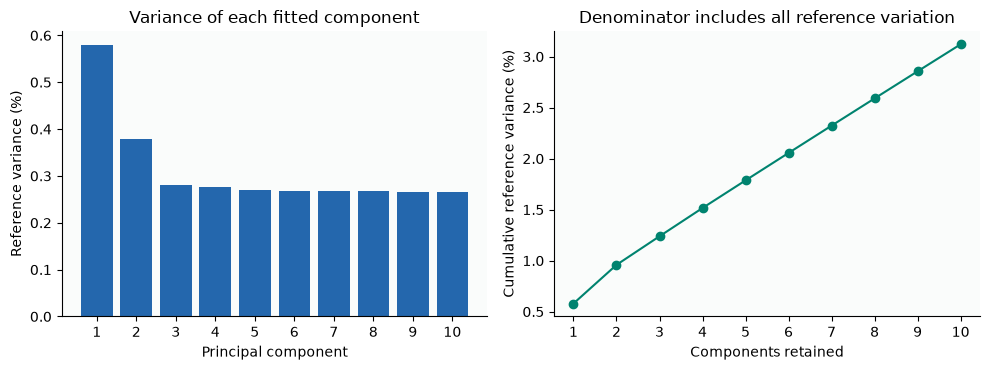

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

axes[0].bar(np.arange(1, 11), variance_pct, color="#2467ad")
axes[0].set(xlabel="Principal component", ylabel="Reference variance (%)",
            title="Variance of each fitted component", xticks=np.arange(1, 11))

axes[1].plot(np.arange(1, 11), variance_pct.cumsum(), "o-", color="#00836f")
axes[1].set(xlabel="Components retained", ylabel="Cumulative reference variance (%)",
            title="Denominator includes all reference variation", xticks=np.arange(1, 11))

fig.tight_layout()
save_figure(fig, "01_reference_variance.png")

print(f"The first two PCs explain {variance_pct[:2].sum():.4f}% of reference variation.")

## 9. Orienting the shape

The raw PC axes have arbitrary orientation and sign. To compare their **shape** with geography, we allow translation, rotation/reflection, and one common scale. A general regression could stretch one axis more than another; this alignment cannot.

Longitude and latitude are not equal local distance units. We use the approximate local plane $x=\lambda\cos\phi_0,\ y=\phi$, where $\phi_0$ is one fixed reference latitude. Plotting degrees with equal aspect without this conversion would change the geographic comparison. This local plane is not a precise distance-preserving projection of the whole Earth.

Let $A$ be the 52 regional mean PC positions and $B$ their locality means in that plane. Means use the predefined calibration subset and give each group equal weight. Center them to $A_c,B_c$ and solve

$$\min_{s,Q}\|sA_cQ-B_c\|_F^2,\qquad Q^\top Q=I.$$

Expanding gives $s^2\|A_c\|_F^2+\|B_c\|_F^2-2s\,\operatorname{tr}(Q^\top A_c^\top B_c)$. If $A_c^\top B_c=U\Sigma V^\top$, maximizing the trace gives $Q=UV^\top$. Differentiating in $s$ gives $s=\operatorname{tr}(\Sigma)/\|A_c\|_F^2$. Finally translate back: $F(P)=s(P-\bar A)Q+\bar B$.

We allow $\det Q=-1$ because a PC sign flip is arbitrary. If reflection were forbidden, the determinant constraint would require a different SVD adjustment. The normalized residual reported below divides squared centroid mismatch by the geographic centroid sum of squares; it is not a percentage of correct locations.

**Why the shape is preserved:** for any two people, $F(P_i)-F(P_j)=s(P_i-P_j)Q$. Orthogonality gives $\|F(P_i)-F(P_j)\|=s\|P_i-P_j\|$. This holds in the plotted plane; it is not a claim about geodesic distances after converting back to longitude/latitude.

In [18]:

calibration = results.loc[results.in_legacy_cohort]

centroids = calibration.groupby("population")[["PC1", "PC2", "longitude", "latitude"]].mean()
A = centroids[["PC1", "PC2"]].to_numpy(dtype=float)
phi0 = float(centroids.latitude.mean())

longitude_factor = float(np.cos(np.radians(phi0)))
B = centroids[["longitude", "latitude"]].to_numpy() * [longitude_factor, 1]

a_mean, b_mean = A.mean(0), B.mean(0)
Ac, Bc = A-a_mean, B-b_mean
U_align, singular_align, Vt_align = np.linalg.svd(Ac.T @ Bc)
Q = U_align @ Vt_align

scale = float(singular_align.sum() / np.square(Ac).sum())

aligned = (results[["PC1", "PC2"]].to_numpy() - a_mean) @ Q * scale + b_mean

results[["RotEW", "RotNS"]] = aligned
results[["rotLon", "rotLat"]] = aligned / [longitude_factor, 1]

disparity = float(np.square(Ac @ Q * scale + b_mean - B).sum() / np.square(Bc).sum())
alignment = {"reference_latitude": phi0, "longitude_factor": longitude_factor,
             "scale": scale, "rotation": Q.tolist(), "pc_center": a_mean.tolist(),
             "planar_center": b_mean.tolist(), "disparity": disparity}

np.testing.assert_allclose(Q.T @ Q, np.eye(2), atol=1e-12)


# A similarity transform multiplies every planar pair distance by the same scale.
pair_index = np.array([[0, 100], [25, 250], [400, 700], [800, 995]])

raw_xy = results[["PC1", "PC2"]].to_numpy()

d_before = np.linalg.norm(raw_xy[pair_index[:, 0]] - raw_xy[pair_index[:, 1]], axis=1)
d_after = np.linalg.norm(aligned[pair_index[:, 0]] - aligned[pair_index[:, 1]], axis=1)

np.testing.assert_allclose(d_after, scale*d_before, atol=1e-10)

display(pd.Series({"Calibration groups": len(centroids), "Reference latitude (degrees)": phi0,
                   "Common scale": scale, "det(Q)": np.linalg.det(Q),
                   "Normalized centroid residual": disparity}, name="Alignment").to_frame())

,Alignment
Calibration groups,52.000000
Reference latitude (degrees),47.050591
Common scale,0.578776
det(Q),1.000000
Normalized centroid residual,0.194905


Geographic data enter **this alignment step**, even though they did not fit the PCA. Thus the accurate statement is that no map is used to learn the genetic axes or impose a coastline, while locality metadata orient the presentation. Plotting the recorded localities themselves is an exact rendering of the metadata, not an independent inference from DNA.

,Comparison,Longitude r,Latitude r
0,Individuals,0.8615,0.8813
1,Regional means,0.9166,0.9002


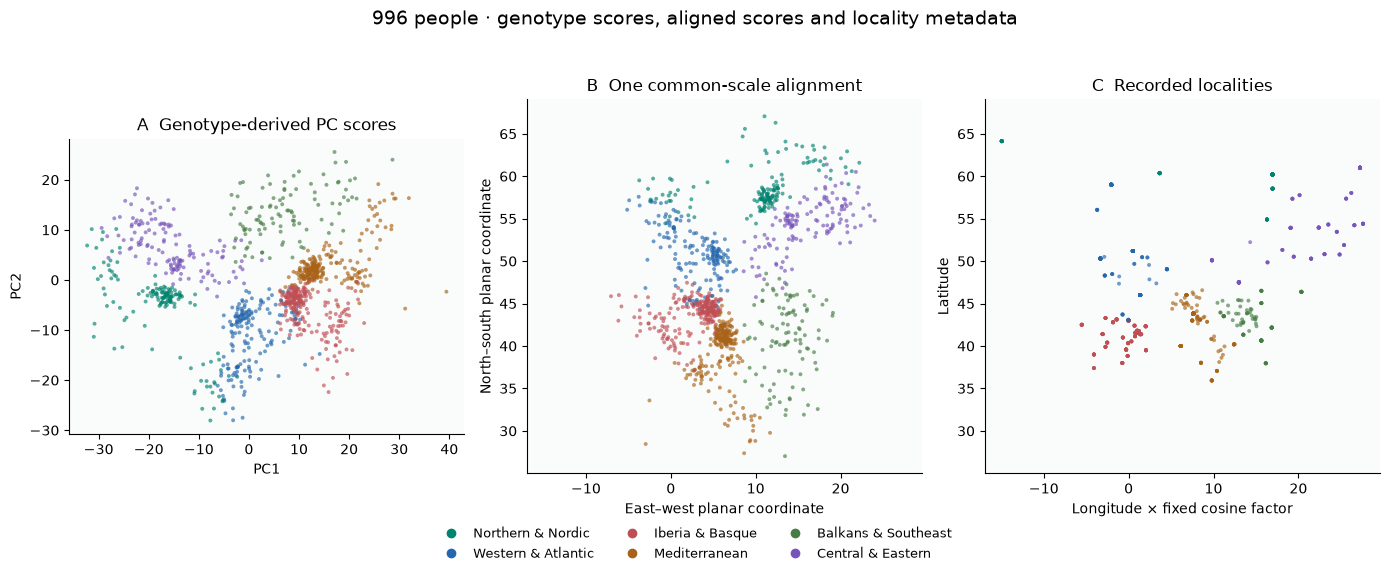

In [19]:
metrics = pipeline.descriptive_metrics(results)
metrics.update(snps_analyzed=G_pruned.shape[1], reference_size=int(reference_mask.sum()))

summary = pd.DataFrame({
    "Comparison": ["Individuals", "Regional means"],
    "Longitude r": [metrics["r_EastWest_Longitude"], metrics["r_centroid_EastWest"]],
    "Latitude r": [metrics["r_NorthSouth_Latitude"], metrics["r_centroid_NorthSouth"]]
})
display(summary.round(4))

fig, axes = plt.subplots(1, 3, figsize=(14, 5.7))
panels = [(raw_xy, "A  Genotype-derived PC scores", "PC1", "PC2"),
          (aligned, "B  One common-scale alignment", "East–west planar coordinate", "North–south planar coordinate"),
          (results[["longitude", "latitude"]].to_numpy()*[longitude_factor, 1],
           "C  Recorded localities", "Longitude × fixed cosine factor", "Latitude")]

for ax, (xy, title, xlabel, ylabel) in zip(axes, panels):
    ax.scatter(*xy.T, s=8, c=colors_for(results), alpha=.65, linewidths=0)
    ax.set_aspect("equal", adjustable="box")
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)

comparison_xy = np.vstack([panels[1][0], panels[2][0]])
low, high = comparison_xy.min(0)-2, comparison_xy.max(0)+2

for ax in axes[1:]:
    ax.set_xlim(low[0], high[0]); ax.set_ylim(low[1], high[1])

fig.legend(handles=region_handles, loc="lower center", ncol=3, frameon=False, fontsize=9)
fig.suptitle("996 people · genotype scores, aligned scores and locality metadata", fontsize=14)

fig.tight_layout(rect=(0, .12, 1, .93))

save_figure(fig, "02_genetic_and_geographic_positions.png")

## 10. Correlation, error and explained variance answer different questions

Pearson correlation is

$$r(x,y)=\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}
{\sqrt{\sum_i(x_i-\bar x)^2\sum_i(y_i-\bar y)^2}}.$$

It measures linear association and is unchanged by adding a constant. A prediction can have correlation 1 while every value is displaced by 10 units. For a regression, $R^2=1-\mathrm{SSE}/\mathrm{SST}$ compares squared prediction residuals with an intercept-only reference; it can be negative on test data. $R^2$ equals squared correlation only under particular fitted-regression conditions, not in general.

PCA explained variance concerns retained genotype variation; coordinate correlations concern association after alignment; kilometre errors concern geographic residuals. None is interchangeable with “percent of Europe recovered.” Here alignment is fitted using locality data and people share regional labels, so ordinary post-fit correlation p-values would not account for those dependencies.

In [20]:
true_values = np.arange(5, dtype=float)
shifted_values = true_values+10
r_example = np.corrcoef(true_values, shifted_values)[0, 1]
r2_example = 1-np.square(shifted_values-true_values).sum()/np.square(true_values-true_values.mean()).sum()


display(pd.Series({"Correlation": r_example, "Mean absolute error (coordinate units)": 10.0,
                   "R^2 against these targets": r2_example}).to_frame("Illustration"))

,Illustration
Correlation,1.0
Mean absolute error (coordinate units),10.0
R^2 against these targets,-49.0


## 11. Why the reference panel matters

PCA is a property of the centered, scaled matrix we fit. Giving a group more rows changes its contribution to covariance; changing the reference also changes allele frequencies and the feature scaling. The design therefore affects the axes even without any geographic targets.

Below we refit frequencies and PCA with equal weight for all 996 people and retain the same marker set and alignment design. The changes quantify reference sensitivity. They do not prove either choice is an unbiased representation of Europe or justify choosing the picture that looks most like a map.

,Fit,r_EastWest_Longitude,r_NorthSouth_Latitude
0,428-person reference,0.8615,0.8813
1,"All 996, equal weight",0.8119,0.8769


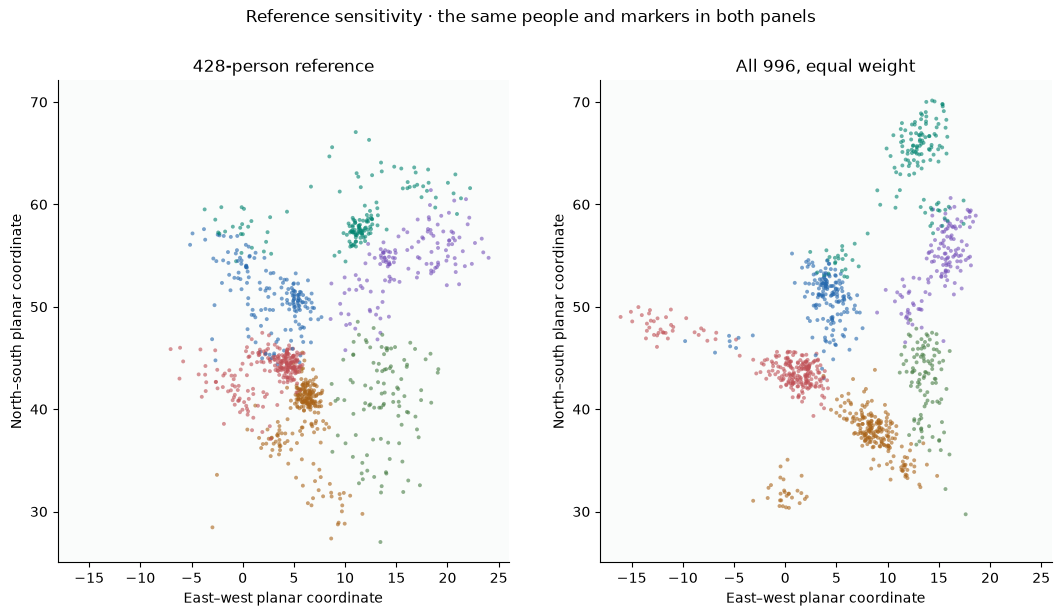

In [21]:
# Refit both allele frequencies and the PCA basis using equal weight for all people.
p_all = np.nanmean(G_pruned, axis=0)/2

denom_all = np.sqrt(2*p_all*(1-p_all))
denom_all[denom_all < 1e-6] = 1

Z_equal = np.nan_to_num((G_pruned-2*p_all)/denom_all, nan=0.0)
model_equal = PCA(n_components=10, random_state=42)
equal_scores = model_equal.fit_transform(Z_equal)
del Z_equal
equal_fit = cohort.copy()
equal_fit[[f"PC{k}" for k in range(1, 11)]] = equal_scores
equal_fit, _ = run_step(pipeline.chunk_8_procrustes_superposition, equal_fit)

sensitivity = pd.DataFrame([
    {"Fit": "428-person reference", **pipeline.descriptive_metrics(results)},
    {"Fit": "All 996, equal weight", **pipeline.descriptive_metrics(equal_fit)}
])

display(sensitivity[["Fit", "r_EastWest_Longitude", "r_NorthSouth_Latitude"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 6))
all_xy = np.vstack([aligned, equal_fit[["RotEW", "RotNS"]].to_numpy()])
lo, hi = all_xy.min(0)-2, all_xy.max(0)+2


for ax, frame, label in zip(axes, [results, equal_fit], sensitivity.Fit):
    ax.scatter(frame.RotEW, frame.RotNS, s=8, c=colors_for(frame), alpha=.6, linewidths=0)
    ax.set_aspect("equal"); ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
    ax.set(title=label, xlabel="East–west planar coordinate", ylabel="North–south planar coordinate")

fig.suptitle("Reference sensitivity · the same people and markers in both panels")

fig.tight_layout(rect=(0, 0, 1, .94))

save_figure(fig, "03_reference_sensitivity.png")

## 12. Supervised mapping: now location is a target


These exploratory experiments used an earlier **634-person cohort** and its preprocessing. They address geographic prediction rather than shape-preserving PCA. The linear fits are reconstructed below from saved, rounded component scores; neural-network, top-50 and loss-function results are loaded from archived reports, **not retrained here or represented as 996-person results**.


Let $D=[\mathbf1,P_1,\ldots,P_k]$ have shape $n\times(k+1)$ and $Y$ contain target longitude/latitude. Ordinary least squares minimizes $\|D\beta-Y\|_F^2$. Differentiating gives $D^\top D\beta=D^\top Y$. If full rank, the symbolic solution is $(D^\top D)^{-1}D^\top Y$, but explicitly forming that inverse is unnecessary and can be unstable. `np.linalg.lstsq` solves the least-squares problem directly, including rank-deficient cases.

The learned coefficient matrix is unconstrained: it can mix PCs and change relative axis scales. Increasing $k$ enlarges the set of training fits available, so optimal unregularized training squared error cannot increase. Held-out geographic error can increase, and great-circle error need not move monotonically with squared degree error.

The code appends an intercept, fits separate target columns together, computes training $R^2$, and then calculates geographic errors. This is an actual refit of the saved component values, not a replayed figure.

In [22]:
ARCHIVE = research / "data/historical_634"
history_files = {name: ARCHIVE/name for name in [
    "top5_pc_regression_summary.csv", "mlp_loo_globe_experiment.csv",
    "top50_mae_experiment.csv", "mlp_mae_by_pcs.csv", "loss_functions_comparison.csv"]}
history = {name: pd.read_csv(path) for name, path in history_files.items()}
historical_hashes = {str(path.relative_to(project)): digest(path) for path in history_files.values()}

# Match the saved component scores to locality metadata by sample ID.
lab = pd.DataFrame(read_js_data(project/"research/data/historical_634/lab_5pc_data.js")["samples"])
archived_metadata = pd.read_csv(ARCHIVE/"human_origins_pca_results.csv")

assert lab.id.is_unique and archived_metadata.sample_id.is_unique
assert set(lab.id) == set(archived_metadata.sample_id) and len(lab) == 634

archived_metadata = archived_metadata.set_index("sample_id").loc[lab.id]
np.testing.assert_allclose(archived_metadata[["longitude", "latitude"]], lab[["lon", "lat"]])
X_legacy = np.array(lab.unw_pcs.tolist())
Y_legacy = lab[["lon", "lat"]].to_numpy()
legacy_colors = [region_colors[r] for r in lab.region]
legacy_factor = np.cos(np.radians(archived_metadata.groupby("population").latitude.mean().mean()))


def reconstruct_historical_ols():
    """Recompute the archived cohort's training fits from its rounded PC scores."""
    rows, predictions = [], {}
    for k in range(1, 6):
        design = np.column_stack([np.ones(len(X_legacy)), X_legacy[:, :k]])
        coefficients = np.linalg.lstsq(design, Y_legacy, rcond=None)[0]
        fitted = design @ coefficients
        predictions[k] = fitted
        r2 = 1-((Y_legacy-fitted)**2).sum(0)/((Y_legacy-Y_legacy.mean(0))**2).sum(0)
        km = haversine_km(*fitted.T, *Y_legacy.T)
        rows.append({"PCs": k, "training_R2_longitude": r2[0],
                     "training_R2_latitude": r2[1], "training_mean_km": km.mean(),
                     "training_median_km": np.median(km)})
    summary = pd.DataFrame(rows)
    report = history["top5_pc_regression_summary.csv"]
    expected = report.loc[(report["mode"] == "Unweighted_All634") & (report.pc_index <= 5)]
    np.testing.assert_allclose(summary[["training_R2_longitude", "training_R2_latitude"]],
        expected[["cumul_r2_lon_pct", "cumul_r2_lat_pct"]].to_numpy()/100, atol=2e-5)
    return summary, predictions

print("Five archived experiment reports loaded; sample IDs and locality joins verified.")

Five archived experiment reports loaded; sample IDs and locality joins verified.


,PCs,training_R2_longitude,training_R2_latitude,training_mean_km,training_median_km
0,1,0.255,0.712,865.366,812.275
1,2,0.661,0.744,579.734,468.406
2,3,0.818,0.775,490.020,445.392
3,4,0.822,0.796,481.612,452.519
4,5,0.824,0.802,477.221,446.620


,pc_name,delta_r2_lon_pct,delta_r2_lat_pct,cumul_r2_lon_pct,cumul_r2_lat_pct
0,PC1,25.463,71.158,25.463,71.158
1,PC2,40.608,3.288,66.071,74.446
2,PC3,15.708,3.073,81.779,77.519
3,PC4,0.430,2.123,82.209,79.642
4,PC5,0.200,0.510,82.409,80.152


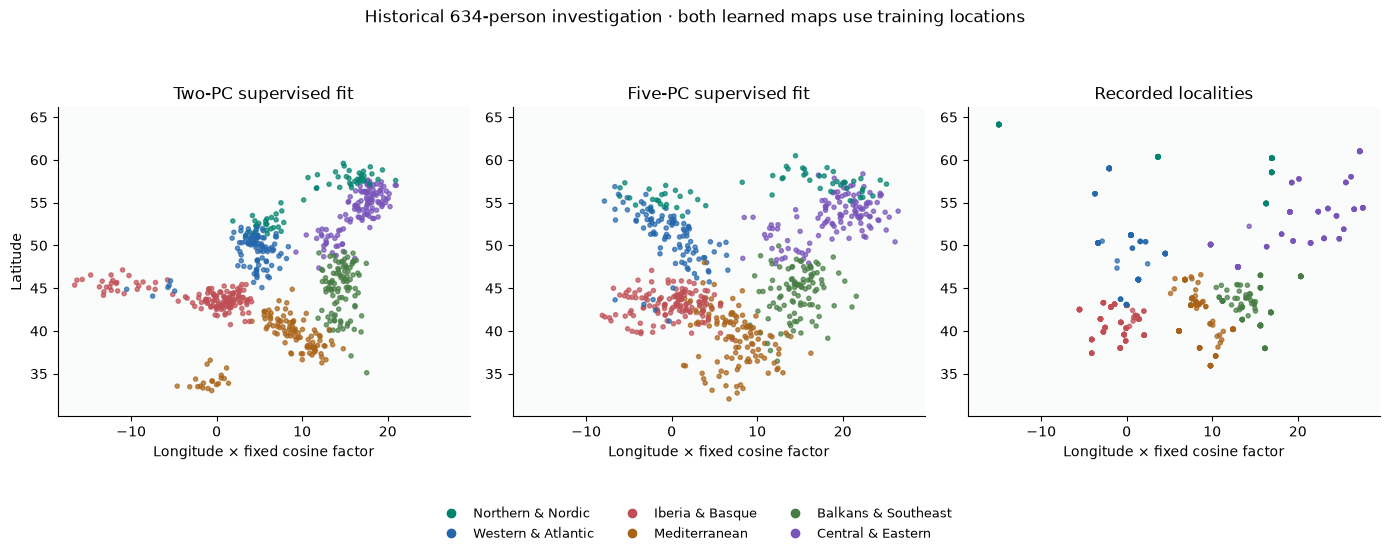

In [23]:
ols_reconstruction, ols_predictions = reconstruct_historical_ols()
display(ols_reconstruction.round(3))
full_precision = history["top5_pc_regression_summary.csv"]
display(full_precision.loc[(full_precision["mode"] == "Unweighted_All634") & (full_precision.pc_index <= 5),
        ["pc_name", "delta_r2_lon_pct", "delta_r2_lat_pct", "cumul_r2_lon_pct", "cumul_r2_lat_pct"]].round(3))
# The rounded-score reconstruction should recover the reported training fit.
expected = full_precision.loc[(full_precision["mode"] == "Unweighted_All634") & (full_precision.pc_index <= 5)]
np.testing.assert_allclose(ols_reconstruction[["training_R2_longitude", "training_R2_latitude"]],
    expected[["cumul_r2_lon_pct", "cumul_r2_lat_pct"]].to_numpy()/100, atol=2e-5)
fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))
fit_clouds = np.vstack([ols_predictions[2], ols_predictions[5], Y_legacy])*[legacy_factor, 1]
fit_low, fit_high = fit_clouds.min(0)-2, fit_clouds.max(0)+2
for ax, xy, title in zip(axes, [ols_predictions[2], ols_predictions[5], Y_legacy],
                        ["Two-PC supervised fit", "Five-PC supervised fit", "Recorded localities"]):
    ax.scatter(xy[:, 0]*legacy_factor, xy[:, 1], s=9, c=legacy_colors, alpha=.7)
    ax.set_aspect("equal", adjustable="box"); ax.set_title(title)
    ax.set_xlabel("Longitude × fixed cosine factor")
    ax.set_xlim(fit_low[0], fit_high[0]); ax.set_ylim(fit_low[1], fit_high[1])
axes[0].set_ylabel("Latitude")
fig.legend(handles=region_handles, loc="lower center", ncol=3, frameon=False, fontsize=9)
fig.suptitle("Historical 634-person investigation · both learned maps use training locations")
fig.tight_layout(rect=(0, .1, 1, 1))
save_figure(fig, "05_supervised_maps.png")

## 13. What a one-hidden-layer neural network adds

A linear map applies one coefficient matrix. A network inserts a nonlinear transform:

$$H=\tanh(XW_1+b_1),\qquad \hat Y=HW_2+b_2.$$

For $N$ people, $d$ input PCs, $h$ hidden units and $o$ output coordinates, shapes are $X:N\times d$, $W_1:d\times h$, $H:N\times h$, $W_2:h\times o$, and $\hat Y:N\times o$. Bias vectors broadcast over rows. The nonlinear `tanh` lets the effective mapping vary across input space; it does not give the network knowledge of coastlines.

The squared-error version of the historical MLP uses

$$L=\frac{1}{2N}\|\hat Y-Y\|_F^2+\frac{\alpha}{2}
(\|W_1\|_F^2+\|W_2\|_F^2).$$

Regularization discourages large weights. For $\Delta=(\hat Y-Y)/N$, backpropagation follows the chain rule:

$$\nabla_{W_2}L=H^\top\Delta+\alpha W_2,\quad
\Delta_1=(\Delta W_2^\top)\odot(1-H^2),\quad
\nabla_{W_1}L=X^\top\Delta_1+\alpha W_1.$$

Bias gradients sum the corresponding row residuals. The historical squared-error code passes these gradients to L-BFGS-B; the loss-variant branch uses Adam-style moment updates. An optimizer's stopping condition is not proof of a global minimum.

The next small example computes a gradient, independently checks it with finite differences, and takes one improving step. It is an invented two-input/two-output calculation, not a new geographic model.

In [24]:
mlp_X = np.array([[-1., .4], [.2, -.5], [.8, .7]])
mlp_Y = np.array([[.1, -.2], [.4, .2], [.7, .5]])
rng = np.random.default_rng(42)
parameters = [rng.normal(0, .2, (2, 3)), np.zeros(3),
              rng.normal(0, .2, (3, 2)), np.zeros(2)]
alpha = .01


def tiny_network_loss(params, gradients=False):
    W1, b1, W2, b2 = params
    H = np.tanh(mlp_X @ W1+b1)
    residual = H @ W2+b2-mlp_Y
    loss = .5*np.square(residual).sum()/len(mlp_X) + .5*alpha*(np.square(W1).sum()+np.square(W2).sum())

    if not gradients:
        return loss
    delta = residual/len(mlp_X)
    delta1 = (delta @ W2.T)*(1-H**2)

    return loss, [mlp_X.T @ delta1+alpha*W1, delta1.sum(0),
                  H.T @ delta+alpha*W2, delta.sum(0)]
loss_before, gradients = tiny_network_loss(parameters, gradients=True)
numeric_errors = []
epsilon = 1e-6

for block, parameter in enumerate(parameters):
    for index in np.ndindex(parameter.shape):
        plus = [v.copy() for v in parameters]; minus = [v.copy() for v in parameters]
        plus[block][index] += epsilon; minus[block][index] -= epsilon
        numeric = (tiny_network_loss(plus)-tiny_network_loss(minus))/(2*epsilon)
        numeric_errors.append(abs(numeric-gradients[block][index]))

assert max(numeric_errors) < 1e-8
updated = [v-.1*g for v,g in zip(parameters, gradients)]
loss_after = tiny_network_loss(updated)

assert loss_after < loss_before

display(pd.Series({"Loss before": loss_before, "Loss after one step": loss_after,
                   "Maximum gradient-check error": max(numeric_errors)}).to_frame("Toy calculation"))

,Toy calculation
Loss before,1.557867e-01
Loss after one step,1.350452e-01
Maximum gradient-check error,1.883218e-11


## 14. What is held out

Training error evaluates targets that influenced the fitted model. A held-out prediction must be generated without fitting to its target. Leaving out one person is not equivalent to leaving out a whole group: in the former, people with the same locality label may remain in training.

For an end-to-end prediction experiment, the training fold must determine marker selection, missing-data handling, frequencies, PCA, model scaling and prediction weights. Test people are transformed with those fitted operations. Hyperparameter selection needs an inner validation loop or a separate validation set; a final test set should not select the winner. [scikit-learn's leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html).

The historical studies fitted PCA before their mapping folds. Some also standardized globally. We preserve their results with that qualification; a held-out mapping target alone does not make the complete analysis independently held out.

The following split illustration uses invented group labels to show exactly which rows remain available. It does not generate a new performance estimate.

In [25]:
toy_groups = np.array(["A", "A", "B", "B", "C", "C"])
held_person = 0
person_test = np.arange(len(toy_groups)) == held_person
group_test = toy_groups == toy_groups[held_person]

display(pd.DataFrame({"Person": np.arange(1, 7), "Group": toy_groups,
                      "One-person test": person_test, "Whole-group test": group_test}))
print("Groups still in training after one-person holdout:", np.unique(toy_groups[~person_test]))
print("Groups still in training after whole-group holdout:", np.unique(toy_groups[~group_test]))

Groups still in training after one-person holdout: ['A' 'B' 'C']
Groups still in training after whole-group holdout: ['B' 'C']


,Person,Group,One-person test,Whole-group test
0,1,A,True,True
1,2,A,False,True
2,3,B,False,False
3,4,B,False,False
4,5,C,False,False
5,6,C,False,False


The five-PC spherical-output comparison reports mean locality errors of approximately **475 km (linear)** and **401 km (MLP)** when one person is held out; holding out a whole regional group raises these to **538 km** and **457 km**. The mapping models standardized inputs and targets within each training fold, but the PCs were fitted beforehand. These are mapping-stage comparisons conditional on that representation, not fully held-out genotype-to-location pipelines. [Implementation](pipeline/run_mlp_loo_experiment.py).

,PCs,Model,Held out,mean_km_err,median_km_err
1,2,Linear,One person,550.0,485.0
3,2,Neural network,One person,430.4,385.2
4,2,Linear,Regional group,594.4,506.7
5,2,Neural network,Regional group,482.1,424.3
7,5,Linear,One person,474.6,450.4
9,5,Neural network,One person,401.1,357.8
10,5,Linear,Regional group,538.2,477.2
11,5,Neural network,Regional group,457.1,413.1


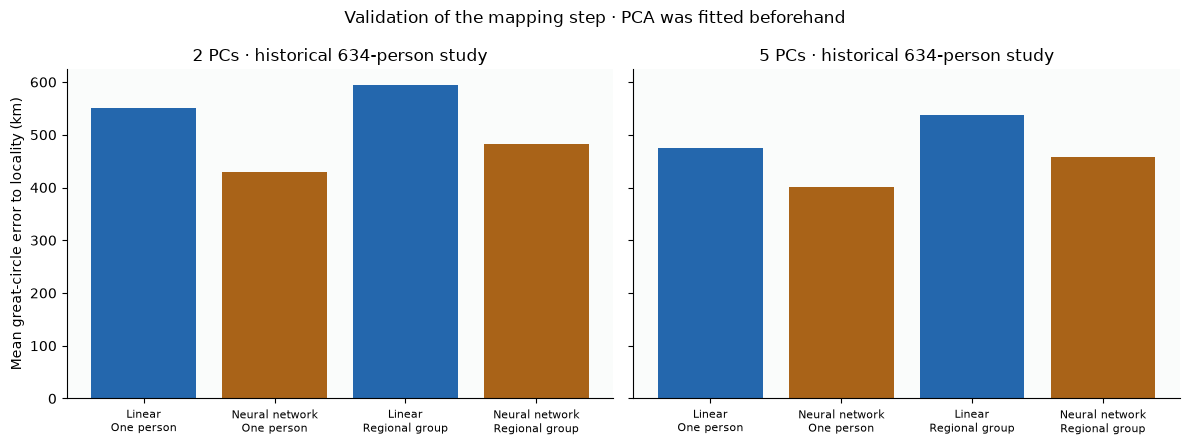

In [26]:
mlp = history["mlp_loo_globe_experiment.csv"].copy()
selected = mlp[mlp.model.str.startswith("Unweighted_PCA_Top") &
               (mlp.model.str.contains("LOO (3D Sphere XYZ)", regex=False) |
                mlp.model.str.contains("LOPO-52", regex=False))].copy()

selected["PCs"] = selected.model.str.extract(r"Top(\d+)PCs").astype(int)
selected["Model"] = np.where(selected.model.str.contains("MLP"), "Neural network", "Linear")
selected["Held out"] = np.where(selected.model.str.contains("LOPO"), "Regional group", "One person")
display(selected[["PCs", "Model", "Held out", "mean_km_err", "median_km_err"]].round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)


for ax, k in zip(axes, [2, 5]):
    rows = selected[selected.PCs == k]
    labels = rows.Model + "\n" + rows["Held out"]
    ax.bar(range(len(rows)), rows.mean_km_err, color=["#2467ad" if m == "Linear" else "#a96318" for m in rows.Model])
    ax.set_xticks(range(len(rows)), labels, fontsize=8)
    ax.set_title(f"{k} PCs · historical 634-person study")

axes[0].set_ylabel("Mean great-circle error to locality (km)")

fig.suptitle("Validation of the mapping step · PCA was fitted beforehand")
fig.tight_layout()
save_figure(fig, "06_mapping_holdouts.png")

## 15. Does keeping 50 PCs solve the problem?


The sweep uses 2, 5, 10, 15, 25 and 50 PCs. Direct fits use 28 hidden units; the 10-fold comparison uses 24 and varies regularization with component count. Training mean error falls from **362 to 192 km**, whereas the mapping-fold error is **353 km at five PCs** and **416 km at fifty**. The separate top-50 suite reports **138 km training** versus **425 km mapping-fold error** for its neural network, under different settings.

These runs do not isolate PC count as the only changing factor. PCA is precomputed in both; the top-50 suite also standardizes globally before its split, while the sweep standardizes within mapping training folds. Both optimize smoothed 3D residuals and report great-circle distances afterwards. [Sweep source](pipeline/run_mlp_mae_by_pcs.py); [top-50 source](pipeline/run_top50_mae_experiment.py).


Extra inputs give a network more ways to fit details. L2 regularization, hidden-layer size, optimization and sample size jointly affect the training/validation gap. The observed gap is consistent with overfitting, but these runs change more than one setting, so they do not isolate a single cause. They also do not establish an optimal PC count for a new population or dataset.

,Model,mae_km,median_km
0,Linear · 2 PCs · mapping folds,535.6,434.9
1,Linear · 5 PCs · mapping folds,452.8,395.2
2,Linear · 15 PCs · mapping folds,445.0,401.9
3,Linear · 50 PCs · mapping folds,457.7,404.8
4,Linear · 50 PCs · training,412.1,357.4
5,MLP · 50 PCs · training,138.3,64.4
6,MLP · 50 PCs · mapping folds,424.6,373.0


mode,Training fit,10-fold mapping comparison
k_pcs,,
2,362.5,373.1
5,341.8,353.2
10,331.8,372.2
15,325.2,373.3
25,294.4,409.0
50,192.2,415.9


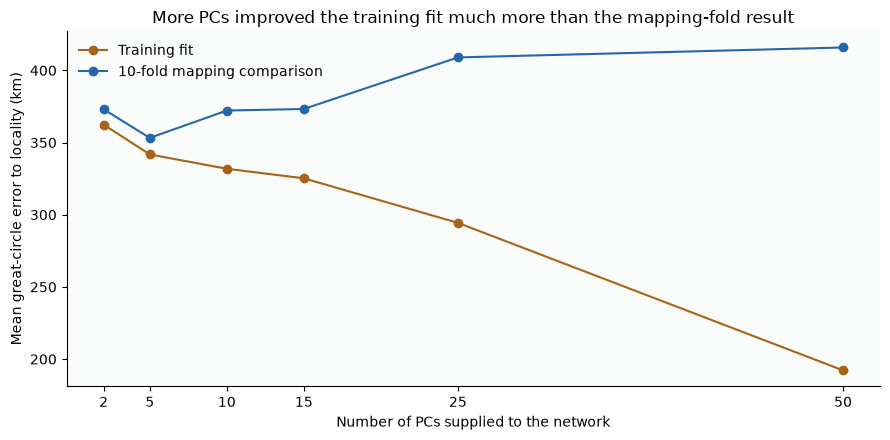

In [27]:
top50 = history["top50_mae_experiment.csv"].copy()
top50["Model"] = ["Linear · 2 PCs · mapping folds", "Linear · 5 PCs · mapping folds",
                      "Linear · 15 PCs · mapping folds", "Linear · 50 PCs · mapping folds",
                      "Linear · 50 PCs · training", "MLP · 50 PCs · training", "MLP · 50 PCs · mapping folds"]
display(top50[["Model", "mae_km", "median_km"]].round(1))
sweep = history["mlp_mae_by_pcs.csv"].copy()
comparison = sweep.pivot(index="k_pcs", columns="mode", values="mae_km")
comparison = comparison.rename(columns={"Direct_Supervised_MAE": "Training fit", "Out_of_Sample_CV_MAE": "10-fold mapping comparison"})
display(comparison.round(1))
fig, ax = plt.subplots(figsize=(9, 4.5))
for label, color in [("Training fit", "#a96318"), ("10-fold mapping comparison", "#2467ad")]:
    ax.plot(comparison.index, comparison[label], "o-", label=label, color=color)
ax.set_xticks(comparison.index)
ax.set_xlabel("Number of PCs supplied to the network")
ax.set_ylabel("Mean great-circle error to locality (km)")
ax.set_title("More PCs improved the training fit much more than the mapping-fold result")
ax.legend(frameon=False)
fig.tight_layout()
save_figure(fig, "07_component_sweep.png")

## 16. Geographic distance and the loss being optimized

A flat degree difference is not a distance in kilometres. On a spherical Earth of radius $R=6371$ km, convert longitude $\lambda$ and latitude $\phi$ to radians. A unit position is

$$u=(\cos\phi\cos\lambda,\ \cos\phi\sin\lambda,\ \sin\phi).$$

For two localities, the haversine expression uses

$$a=\sin^2\frac{\Delta\phi}{2}+\cos\phi_1\cos\phi_2\sin^2\frac{\Delta\lambda}{2},
\qquad d=2R\arcsin\sqrt a.$$

Clipping $a$ to $[0,1]$ prevents rounding errors from making the square root/arcsine invalid. For unit vectors separated by angle $\theta$, chord distance is $2R\sin(\theta/2)$, while surface distance is $R\theta$. They agree approximately at short separations, not exactly.

The PC-sweep source minimizes a **smoothed Euclidean 3D residual** before normalizing predicted vectors back onto the sphere. Its predictions need not have unit norm during optimization, so its loss is not even exactly the unit-vector chord formula. Geographic errors are reported after conversion. Names in older reports such as “great-circle L1” must be read against the implemented objective.

,Toy geometry
90-degree surface distance (km),10007.543398
90-degree straight chord (km),9009.954606


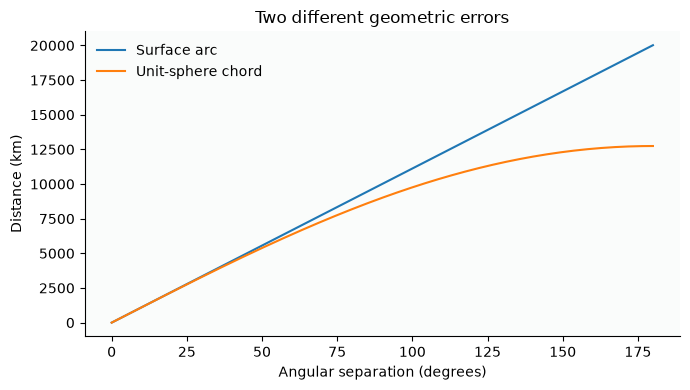

In [28]:
def lonlat_unit(lon, lat):
    lam, phi = np.radians(lon), np.radians(lat)
    return np.array([np.cos(phi)*np.cos(lam), np.cos(phi)*np.sin(lam), np.sin(phi)])

u1, u2 = lonlat_unit(0, 0), lonlat_unit(90, 0)
arc = haversine_km(0, 0, 90, 0)
chord = 6371*np.linalg.norm(u1-u2)
np.testing.assert_allclose(arc, np.pi*6371/2)

display(pd.Series({"90-degree surface distance (km)": arc,
                   "90-degree straight chord (km)": chord}).to_frame("Toy geometry"))

theta = np.linspace(0, np.pi, 200)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.degrees(theta), 6371*theta, label="Surface arc")
ax.plot(np.degrees(theta), 2*6371*np.sin(theta/2), label="Unit-sphere chord")
ax.set(xlabel="Angular separation (degrees)", ylabel="Distance (km)", title="Two different geometric errors")
ax.legend(frameon=False); fig.tight_layout()

save_figure(fig, "toy_chord_and_arc.png")

### 16.1 Squared, absolute, robust and spread objectives

For a scalar residual $e$, standard examples are:

$$L_2(e)=\tfrac12e^2,\qquad L_1(e)=|e|,$$
$$L_{\mathrm{Huber}}(e)=
\begin{cases}\tfrac12e^2,&|e|\le\delta\\
\delta(|e|-\tfrac12\delta),&|e|>\delta,\end{cases}
\qquad
L_{\mathrm{Cauchy}}(e)=\tfrac{c^2}{2}\log(1+(e/c)^2).$$

Squared loss grows quickly for large errors; Huber is quadratic near zero and linear in its tails; Cauchy reduces the influence of very large residuals more strongly. None is universally best, and downweighting a residual is not evidence that the observation is wrong.

These equations teach the standard scalar losses. The historical experiment uses vector residuals, standardized targets and custom gradient scales, so its variants are labeled **Huber-like/Cauchy-like**, not certified implementations of these exact scalar objectives.

A spread penalty can have the form $\gamma\sum_j(\operatorname{sd}(\hat Y_j)-t_j)^2$. It encourages a chosen output dispersion but does not say which person belongs where. You can preserve spread while assigning everyone the wrong position. In the archived spread variant, the target statistic is globally estimated and multiplied by 1.02; there is no land or coastline mask.

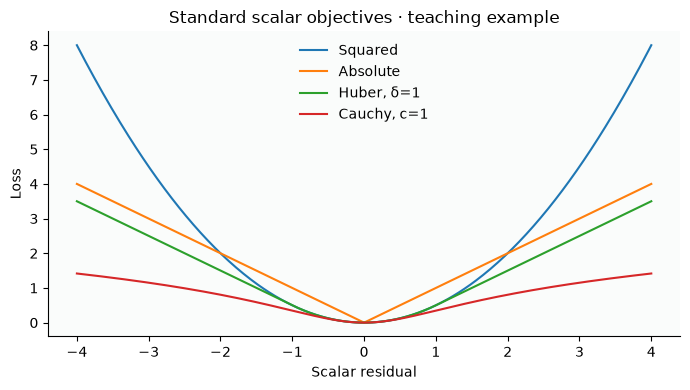

In [29]:
residual_grid = np.linspace(-4, 4, 401)
delta, cauchy_scale = 1.0, 1.0

standard_losses = {
    "Squared": .5*residual_grid**2,
    "Absolute": np.abs(residual_grid),
    "Huber, δ=1": np.where(np.abs(residual_grid)<=delta, .5*residual_grid**2,
                          delta*(np.abs(residual_grid)-.5*delta)),
    "Cauchy, c=1": .5*cauchy_scale**2*np.log1p((residual_grid/cauchy_scale)**2)}

fig, ax = plt.subplots(figsize=(7, 4))

for label, values in standard_losses.items():
    ax.plot(residual_grid, values, label=label)

ax.set(xlabel="Scalar residual", ylabel="Loss", title="Standard scalar objectives · teaching example")
ax.legend(frameon=False); fig.tight_layout()

save_figure(fig, "toy_standard_loss_curves.png")

The six variants compare squared error, smoothed 3D residuals, Huber-like and Cauchy-like residual weighting, and a target-spread term. Labels below describe the implementation. The spread term uses output standard deviations; it never reads a coastline polygon.

These are exploratory results: PCA, global input/target standardization and the target-spread statistic were computed before the mapping folds. Custom gradient scaling has not been independently validated. Thus these values do not establish clean predictive superiority for a standard named loss. The spread variant gives approximately **365 km mean error**, versus **343 km** for the smoothed-3D-residual variant, despite better dispersion matching. [Implemented experiments](pipeline/compare_loss_functions.py).

,Implemented variant,mean_km,median_km,lon_spread_pct,lat_spread_pct
0,Planar squared error,361.3,317.1,92.5,93.0
1,Standardized XYZ squared error,355.1,317.1,91.9,94.5
2,Smoothed 3D residual,343.0,301.3,88.2,92.9
3,Huber-like residual weighting,351.0,306.9,87.6,91.7
4,Cauchy-like residual weighting,362.0,319.3,84.6,89.5
5,Huber-like plus target spread,364.7,323.2,94.4,95.8


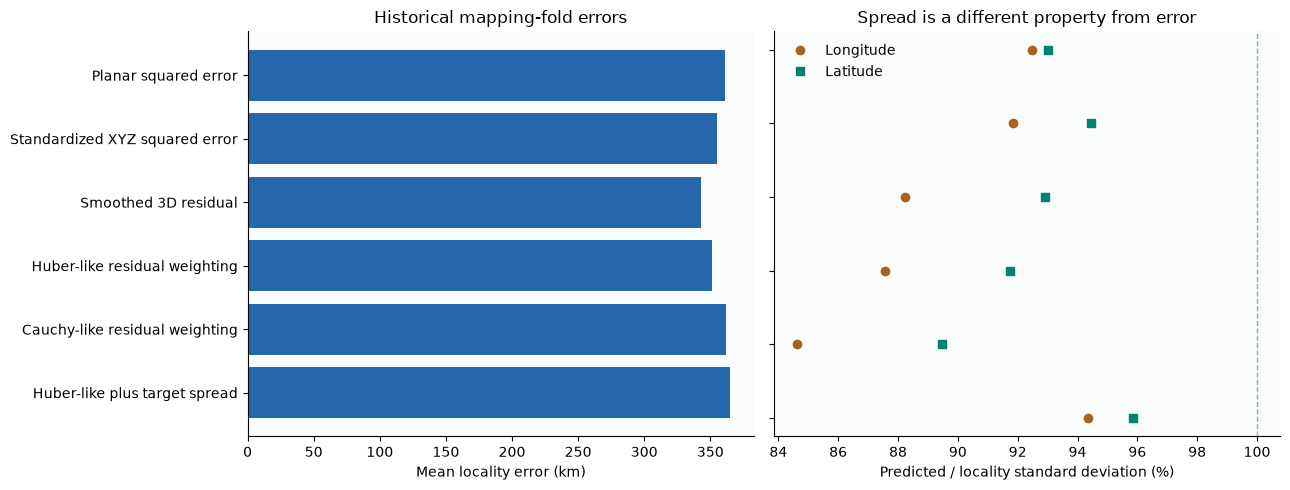

In [30]:
losses = history["loss_functions_comparison.csv"].copy()
loss_labels = ["Planar squared error", "Standardized XYZ squared error", "Smoothed 3D residual",
               "Huber-like residual weighting", "Cauchy-like residual weighting", "Huber-like plus target spread"]
assert len(losses) == len(loss_labels)
losses["Implemented variant"] = loss_labels

display(losses[["Implemented variant", "mean_km", "median_km", "lon_spread_pct", "lat_spread_pct"]].round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
y = np.arange(len(losses))
axes[0].barh(y, losses.mean_km, color="#2467ad")
axes[0].set_yticks(y, loss_labels); axes[0].invert_yaxis()
axes[0].set_xlabel("Mean locality error (km)"); axes[0].set_title("Historical mapping-fold errors")
axes[1].plot(losses.lon_spread_pct, y, "o", label="Longitude", color="#a96318")
axes[1].plot(losses.lat_spread_pct, y, "s", label="Latitude", color="#00836f")
axes[1].axvline(100, color="#9aa9ad", lw=1, ls="--")
axes[1].set_yticks(y, []); axes[1].invert_yaxis(); axes[1].set_xlabel("Predicted / locality standard deviation (%)")
axes[1].set_title("Spread is a different property from error"); axes[1].legend(frameon=False)

fig.tight_layout()

save_figure(fig, "08_loss_and_dispersion.png")

## 17. Connect the mathematics back to the claim

| Operation | What is learned or supplied | What the resulting picture can support |
|---|---|---|
| Reference PCA | Genotype variation and reference design | A low-dimensional genetic arrangement |
| Similarity alignment | Regional locality means, one scale and orientation | Shape correspondence in a common plane |
| OLS or neural mapping | Geographic targets and flexible coefficients | Geographic fit/prediction under its validation design |
| Plotting locality metadata | Recorded coordinates directly | The sampling/locality arrangement |
| A country-specific shift | An extra manual adjustment | A changed display, no longer the single PCA geometry |

The compelling result is that a genetic summary contains a recognizable spatial arrangement before any coastline is drawn. Its meaning depends on stating that geography later supplies orientation, the sample/reference are selected, and the two dimensions are a compressed view. The mismatches are evidence to study, not drawing errors to erase.

### Check your understanding

1. Why must missing genotypes differ from dosage zero?
2. Which people determine $p_j$, and which determine the LD filter?
3. Is a dot a row of $V$, a row of $U$, or a row of the score matrix?
4. Why can a single scale preserve shape while separate x/y scales cannot?
5. Can a prediction have correlation 1 and substantial geographic error?
6. Why is a low training error at 50 PCs insufficient?

**Answers.** Missing is unknown while zero is an observed allele count. The PCA reference determines normalization; the core QC panel determines LD here. A dot is a score row ($XV$). One scale multiplies every planar pair distance equally. Correlation ignores a constant displacement and positive rescaling. More flexible models can fit training details; prediction needs an appropriate held-out pipeline and validation design.

## 18. Verify the calculation and save the working record

The same checks as in the technical report compare all ten real PC scores and aligned positions to the final data. Toy eigenanalysis, score multiplication, reconstruction, gradient and geometry checks already ran at their explanatory steps. Historical model reports are preserved, not silently retrained. Input/source hashes and package versions are written to this version's working directory.

In [31]:
canonical = pd.read_csv(research/"results/stats/human_origins_pca_results.csv").set_index("sample_id")
computed = results.set_index("sample_id").loc[canonical.index]
assert len(computed) == 996 and set(computed.index) == set(canonical.index)
columns = [*[f"PC{k}" for k in range(1, 11)], "RotEW", "RotNS", "rotLon", "rotLat"]
np.testing.assert_allclose(computed[columns], canonical[columns], rtol=2e-5, atol=2e-5)
for rel, expected_hash in {**protected_hashes, **historical_hashes}.items():
    assert digest(project/rel) == expected_hash, f"Protected file changed: {rel}"

results.to_csv(pipeline.STATS/"human_origins_pca_results.csv", index=False)
summary.to_csv(pipeline.STATS/"descriptive_correlations.csv", index=False)
sensitivity.to_csv(pipeline.STATS/"reference_sensitivity.csv", index=False)
ols_reconstruction, _ = reconstruct_historical_ols()
ols_reconstruction.to_csv(pipeline.STATS/"historical_ols_reconstruction.csv", index=False)
(pipeline.STATS/"alignment_transform.json").write_text(json.dumps(alignment, indent=2)+"\n")
run_step(pipeline.write_run_manifest, cohort, retained_snps, metrics)
checks = {"Current individuals": len(computed), "Retained markers": G_pruned.shape[1],
          "Current scores and alignment agree with final data": "PASS",
          "Common scale preserves planar shape": "PASS",
          "App and canonical outputs unchanged": "PASS",
          "Archived reports unchanged": "PASS"}
display(pd.Series(checks, name="Result").to_frame())
(pipeline.STATS/"notebook_provenance.json").write_text(json.dumps({
    "notebook": "genes_mirror_geography_math_code.ipynb", "current_cohort": 996,
    "historical_model_cohort": 634,
    "recomputed": ["genotype QC", "reference PCA", "similarity alignment",
                   "equal-weight sensitivity", "rounded-score historical OLS"],
    "loaded_model_reports": list(history_files),
    "historical_report_sha256": historical_hashes,
    "checks": checks
}, indent=2)+"\n")

Out[31]: 1458


,Result
Current individuals,996
Retained markers,46213
Current scores and alignment agree with final data,PASS
Common scale preserves planar shape,PASS
App and canonical outputs unchanged,PASS
Archived reports unchanged,PASS


## References and implementation trail


- Novembre et al. (2008), *Genes mirror geography within Europe*, Nature 456:98–101, particularly Figure 1 and Methods. This project uses AADR, not the paper's POPRES dataset.
- Patterson, Price & Reich (2006), [Population Structure and Eigenanalysis](https://journals.plos.org/plosgenetics/article?id=10.1371/journal.pgen.0020190), for population-genetic PCA.
- [scikit-learn PCA documentation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), for the estimator's centering, component and variance conventions; [preprocessing and leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html), for validation design.
- [TGENO format specification](https://github.com/DReichLab/AdmixTools/blob/master/transpose_info/transpose_format.txt).
- Local inputs and software versions are recorded in this notebook's `run_manifest.json`. Archived experiment scripts are linked at the relevant analyses.


The notebook exposes normalization, PCA, alignment, OLS and the chain-rule example in cells. The final [pipeline](pipeline/run_human_origins_pca.py) implements the chosen study, historical model sources explain the earlier predictive experiments. The [technical report](genes_mirror_geography_replication.ipynb) presents the evidence without the learning exercises.